# 08 · More rules: the learners decomposed, the polynomial degree, and short-dated options

Three sets of rules were added on 2026-11-05, each specified and committed before its run:
- **R5–R8 under every protocol** (plan §16.4).
- **R9–R11** (§16.7). With R8 they form a 2×2 design: a LightGBM correction learned from scratch (R9, R10) or boosted from R2 (R11, R8), on δ alone (R9, R11) or on six features (R10, R8).
- **P0–P8 and PCV** (§16.8): R2's quadratic replaced by a polynomial of degree 0–8, and a degree chosen by validation inside each training window.

Plus **short-dated options** (§16.6): under 14 days, each pair ending before settlement. All of this is exploratory: it was specified after the 2020 test had been seen.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

## 2020: the learners under the Table 8.1 variants (Gain over R2)

In [2]:
lv = pd.read_csv(R / "2020/learners_variants.csv"); r9 = pd.read_csv(R / "2020/r9_r11.csv")
both = pd.concat([lv[lv.base == "R2"], r9[(r9.base == "R2") & r9.rule.isin(["R9", "R10", "R11"])]])
both.pivot_table(index="variant", columns=["rule", "cp"], values="gain").round(3)

rule                         R10            R11            R8             R9       
cp                             C       P      C      P      C       P      C      P
variant                                                                            
A                          0.084  -0.541  0.001 -0.000  0.123  -0.563  0.009  0.004
B                         -0.119 -19.268  0.001 -0.002 -0.182 -16.910  0.008  0.001
F                         -0.007  -0.062  0.000 -0.000 -0.027  -0.130 -0.002 -0.004
OTM                        0.034  -9.722  0.001 -0.000 -0.025  -7.698 -0.013  0.012
OTM-refit                    NaN     NaN    NaN    NaN -0.028  -7.687    NaN    NaN
P-SW                       0.054 -10.026  0.000 -0.002  0.035  -9.943  0.007  0.000
P-WM                       0.018  -6.906  0.000 -0.003 -0.017  -9.568  0.007  0.002
P-ask                      0.075 -11.360  0.000 -0.003  0.113 -11.311  0.005  0.006
P-bid                     -0.133  -5.961  0.000 -0.002 -0.148  -6.364  0.006 -0.002
S3                         0.065 -10.338  0.001 -0.004  0.027  -8.823  0.013  0.001
T                          0.088 -11.290  0.001 -0.003  0.072 -11.049  0.008  0.002
V                          0.047 -11.044  0.000 -0.003 -0.023  -9.165  0.008  0.001
W36                       -0.048  -0.429  0.000 -0.002 -0.042  -0.970  0.003 -0.001
W60                       -0.157  -0.484  0.000 -0.002 -0.105  -1.082  0.002 -0.002
day-two volume 0 or empty  0.042 -12.212  0.001 -0.001 -0.008 -10.331 -0.003  0.004
day-two volume > 0         0.049 -10.761  0.000 -0.003 -0.029  -8.892  0.012  0.000
primary                    0.047 -11.121  0.000 -0.003    NaN     NaN  0.008  0.001
primary, block 20          0.047 -11.121  0.000 -0.003 -0.023  -9.249  0.008  0.001
primary, block 5           0.047 -11.121  0.000 -0.003 -0.023  -9.249  0.008  0.001
rest of 2020              -0.003  -0.121 -0.002 -0.000 -0.007  -0.133  0.014  0.019
stress                     0.060 -12.843  0.001 -0.003 -0.027 -10.676  0.006 -0.002

**Reading.** Both learners that use the six features (R8, R10) collapse for puts in most variants: the March 2020 crash pushed volatility and returns far outside their calm training range. Both δ-only learners (R9, R11) stay within ±0.02 of R2 everywhere. The features broke R8, not the boosting.

## The walk-forward, 2011–2023: median yearly Gains over 2015–2023

In [3]:
med = pd.concat([pd.read_csv(R / f"walkforward/{f}.csv") for f in
                 ("median_yearly_gain", "r5_r8_median_yearly_gain", "r9_r11_median_yearly_gain", "degrees_median_yearly_gain")])
med = med.drop(columns=[c for c in ("sample",) if c in med]).drop_duplicates(["window", "cp", "rule", "base"])
med.pivot_table(index="rule", columns=["base", "window", "cp"], values="median_yearly_gain").round(3)

base       R1                                        R2                                   
window     12            36            60            12            36            60       
cp          C      P      C      P      C      P      C      P      C      P      C      P
rule                                                                                      
P0      0.119  0.105  0.157  0.158  0.156  0.159 -0.002 -0.001 -0.000 -0.004 -0.001 -0.004
P1      0.118  0.103  0.157  0.161  0.156  0.163 -0.002  0.000 -0.001  0.000 -0.001 -0.000
P2      0.124  0.100  0.157  0.158  0.157  0.160 -0.000  0.000 -0.000  0.000 -0.000  0.000
P3      0.123  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
P4      0.123  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
P5      0.123  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
P6      0.123  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
P7      0.123  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
P8      0.123  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
PCV     0.122  0.103  0.149  0.158  0.149  0.159  0.001  0.001  0.001 -0.000  0.001 -0.000
R10     0.071  0.041  0.083  0.158  0.125  0.153 -0.006 -0.003 -0.023 -0.007 -0.013  0.001
R11     0.124  0.101  0.157  0.159  0.157  0.160  0.000  0.000  0.000  0.000  0.000  0.000
R2      0.124  0.100  0.157  0.158  0.157  0.160    NaN    NaN    NaN    NaN    NaN    NaN
R5      0.124  0.102  0.157  0.159  0.157  0.160  0.001  0.000  0.000  0.000  0.000  0.000
R6      0.117  0.071  0.139  0.146  0.140  0.148 -0.011 -0.004 -0.016 -0.006 -0.016 -0.007
R8      0.122  0.037  0.094  0.161  0.124  0.158 -0.001  0.001 -0.008 -0.007 -0.007 -0.001
R9      0.120  0.104  0.160  0.160  0.159  0.161  0.001  0.001  0.002  0.001  0.002  0.001

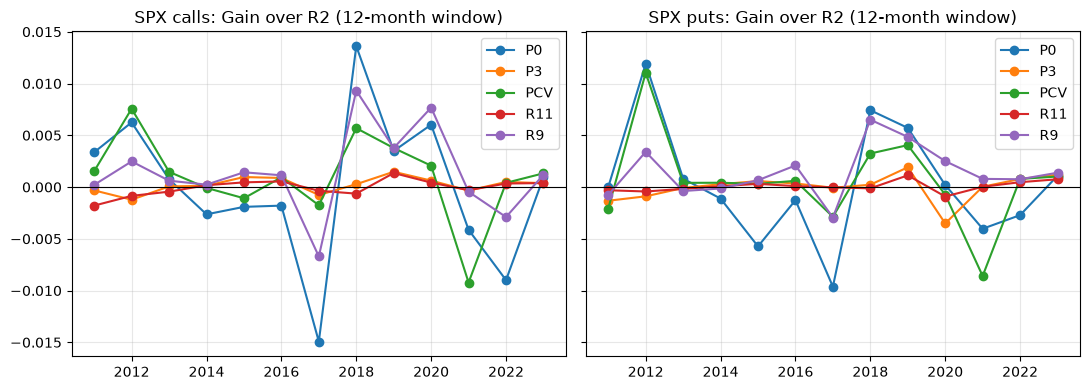

In [4]:
d = pd.read_csv(R / "walkforward/degrees_by_year.csv"); r9w = pd.read_csv(R / "walkforward/r9_r11_by_year.csv")
x = pd.concat([d[(d.base == "R2") & d.rule.isin(["P0", "P3", "PCV"])], r9w[(r9w.base == "R2") & r9w.rule.isin(["R9", "R11"])]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cp, nm in zip(axes, "CP", ("calls", "puts")):
    for rule, z in x[(x.window == 12) & (x.cp == cp)].groupby("rule"):
        z = z.sort_values("year"); ax.plot(z.year, z.gain, marker="o", label=rule)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"SPX {nm}: Gain over R2 (12-month window)"); ax.legend()
plt.tight_layout()

In [5]:
c = pd.read_csv(R / "walkforward/degrees_pcv_choice.csv")
c.groupby(["window", "cp"]).degree.value_counts().unstack(fill_value=0)

degree      0   1   2   3   4   5  6  7   8
window cp                                  
12     C   59   5  19  18  14  16  4  3  18
       P   61  25   3  17   3  26  6  3  12
36     C   64   5  27   3   4  10  7  5   7
       P   65  24   9   7   0  13  4  1   9
60     C   47  11  21   2   5   8  6  2   6
       P   54  25   7   7   2   3  4  0   6

**Reading.**
- **Every rule built on Hull–White's form tracks R2 within a few thousandths a year.** On SPX, R5 equals R2; R9 gains about +0.001 to +0.002; P3–P8 add nothing.
- **The constant P0 is about as good as R2,** and better in 2022–2023 for puts on the long windows.
- **PCV mostly picks degree 0.** It is never significantly worse than R2.
- **The more flexible learner does worse:** R10.

## Why R9's tuned correction is nearly constant

Refit on 2019 (the window that feeds January 2020): R2's quadratic, R9's tuned h(δ) and the constant fit, as corrections g(δ) in the hedge δ + ν/(S√τ)·g(δ). The x² weights that the loss uses peak near the money.

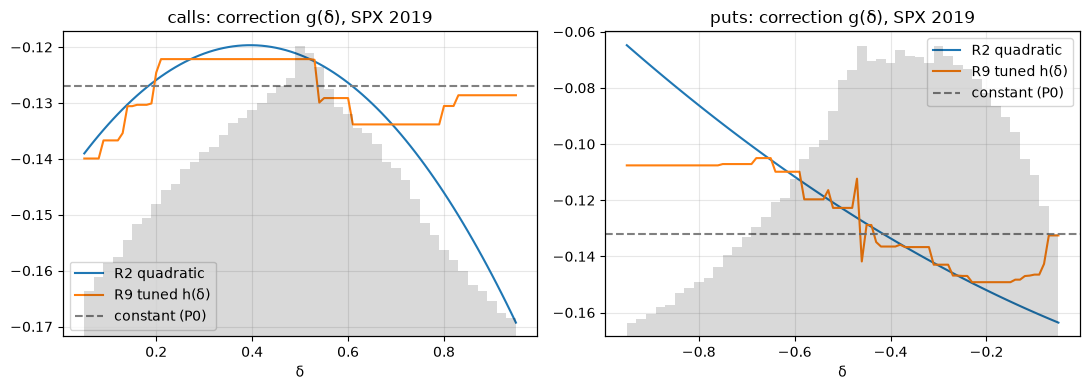

In [6]:
from erdos_quant_finance_project import hedging as h, learners as L
P = h.load_pairs([2018, 2019]); P = P[P.next_session < h.UNBLIND]
fr = h.ingredients(P); z = L.features(fr, P); ok = L.complete(fr, z)
p9 = json.loads((R / "rehearsal/r9_params_2019.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cp in zip(axes, "CP"):
    tr = ok & (fr.cp == cp) & (P.quote_date >= "2019-01-01"); dd = fr[tr]
    beta = h.ols(*h.design("R2", dd)); c0 = float((dd.x * dd.y).sum() / (dd.x ** 2).sum())
    m9 = L.fit_direct(dd, z[tr][["delta"]], p9[cp])
    grid = np.linspace(0.05, 0.95, 91) * (1 if cp == "C" else -1)
    ax.plot(grid, h.poly(grid) @ beta, label="R2 quadratic"); ax.plot(grid, m9.predict(grid[:, None]), label="R9 tuned h(δ)")
    ax.axhline(c0, ls="--", color="gray", label="constant (P0)")
    ax2 = ax.twinx(); ax2.hist(dd.delta, bins=45, weights=dd.x ** 2, alpha=0.15, color="k"); ax2.set_yticks([])
    ax.set_title({"C": "calls", "P": "puts"}[cp] + ": correction g(δ), SPX 2019"); ax.set_xlabel("δ"); ax.legend()
plt.tight_layout()

**Reading.** R9 follows R2's shape where the weight lies and flattens toward the constant in the tails. R2's own curve is nearly flat there too. Out of sample on its 2019 tuning folds, the constant matched R2 (+0.014 for calls, +0.000 for puts). Validation therefore shrinks R9 toward a constant: with all options on a session sharing one index move, about 125 independent shocks per fold cannot support much δ-shape. Details: `notes/unified-results.md` §3.2.

## Short-dated options (under 14 days)

In [7]:
s = pd.read_csv(R / "short_dated/gains_by_year.csv")
s[s.rule.isin(["R2m", "R2s"])].pivot_table(index="year", columns=["rule", "base", "cp"], values="gain").round(3)

rule    R2m           R2s                     
base     R1            R1           R2m       
cp        C      P      C      P      C      P
year                                          
2011  0.109  0.127  0.060  0.057 -0.055 -0.081
2012 -0.184 -0.153 -0.172 -0.120  0.010  0.028
2013  0.014  0.005 -0.010 -0.039 -0.025 -0.044
2014  0.033  0.008  0.025  0.010 -0.008  0.002
2015  0.043  0.017  0.050  0.044  0.007  0.028
2016  0.063 -0.010  0.056  0.017 -0.008  0.026
2017  0.061 -0.006  0.081  0.025  0.022  0.031
2018  0.038  0.052 -0.001 -0.017 -0.041 -0.073
2019  0.082  0.015  0.042 -0.011 -0.044 -0.026
2020  0.156  0.005  0.146 -0.017 -0.012 -0.022
2021  0.147  0.107  0.155  0.109  0.009  0.002
2022  0.025 -0.016 -0.015 -0.048 -0.042 -0.031
2023  0.002 -0.022 -0.004 -0.044 -0.006 -0.021

In [8]:
b = pd.read_csv(R / "short_dated/buckets.csv")
b.groupby(["cp", "days"])[["G_R2m_R1", "G_R2s_R1", "pairs"]].median().round(3)

G_R2m_R1  G_R2s_R1    pairs
cp days                             
C  0-2      0.003    -0.019   1738.0
   3-6      0.025    -0.011   6176.0
   7-13     0.087     0.072  17515.0
P  0-2     -0.016    -0.034   1757.0
   3-6     -0.022    -0.030   6467.0
   7-13     0.033     0.013  19511.0

**Reading.** Close to expiry, vega is small and the correction has little to work with. R2's coefficients from options of 14 days or more (R2m) gain a median 0.06 for calls and 0.005 for puts over Black–Scholes. That comes mainly from the 7–13-day options. Refitting on short-dated options (R2s) does not help.